## Corrected Local FFT Propagation

This notebook compares four propagation estimates:

1. The full-record FFT reference

\[
\psi_{\mathrm{full}} = \mathrm{IFFT}\{\mathrm{FFT}(u)H\}
\]

2. The current past-only local FFT baseline, which uses the latest `block_len` samples and extracts the last sample.

3. A causal FIR approximation built from the local FFT propagation kernel after zeroing the wrapped negative-lag impulse-response support. This uses only present and past samples.

4. A centered local FFT approximation, which uses samples around the requested time and extracts the center sample. This introduces latency, but it tests whether the previous failure was mainly caused by causality/extraction rather than by the propagation kernel itself.


In [1]:
from pathlib import Path
import os
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import signal
from scipy.fft import fft, ifft
from scipy.io import loadmat


project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
output_file = project_root / "data" / "interim" / "refractive_phase_psd.mat"
output_dir = project_root / "outputs" / "overlap_save_propagation"
output_dir.mkdir(parents=True, exist_ok=True)

config = {
    "run_matlab": False,
    "matlab_cmd": os.environ.get("MATLAB_CMD", "matlab"),
    "output_file": output_file,
    "output_dir": output_dir,
    "rhof_veff_ratio": 2.0,
    "U": 2.0,
    "p1": 2.2,
    "p2": 3.8,
    "mu0": 1.0,
    "sim_time": 300.0,
    "t_samp": 0.02,
    "seed": 123,
    "block_lengths": [512, 800, 1024, 1500, 2000, 3000, 4096, 6000, 8000],
    "window_list": [None, "hann", "hamming", "tukey"],
    "plot_start": 4000,
    "n_plot": 1200,
    "edge_factor": 1,
    "causal_include_zero_lag": True,
}


def q(value):
    return "'" + str(value).replace("'", "''") + "'"


if config["run_matlab"]:
    matlab_code = f"""
addpath({q(project_root / 'tools' / 'cpssm_utils')});
get_refractive_phase_psd( ...
    'output_file', {q(config['output_file'])}, ...
    'rhof_veff_ratio', {config['rhof_veff_ratio']}, ...
    'U', {config['U']}, ...
    'p1', {config['p1']}, ...
    'p2', {config['p2']}, ...
    'mu0', {config['mu0']}, ...
    'sim_time', {config['sim_time']}, ...
    't_samp', {config['t_samp']}, ...
    'seed', {config['seed']});
"""
    subprocess.run([config["matlab_cmd"], "-batch", matlab_code], cwd=project_root, check=True)

if not output_file.exists():
    raise FileNotFoundError(
        f"Missing {output_file}. Set config['run_matlab'] = True or run the data-generation notebook first."
    )

mat = loadmat(output_file, squeeze_me=True)
phi_R = np.ravel(mat["phi_R"]).astype(float)
Fs = float(np.asarray(mat["sample_rate_hz"]).squeeze())
dt = float(np.asarray(mat["sample_interval_s"]).squeeze())
rho_over_v = float(np.asarray(mat["rhof_veff_ratio"]).squeeze())
N_fft = int(np.asarray(mat["nfft"]).squeeze())

u = np.exp(1j * phi_R)
N = len(u)

f_full = np.fft.fftfreq(N, d=dt)
H_full = np.exp(-0.5j * (2 * np.pi * f_full * rho_over_v) ** 2)
psi_full = ifft(fft(u, n=N) * H_full)
amp_full = np.abs(psi_full)
phase_full = np.unwrap(np.angle(psi_full))

init_summary = {
    "N": N,
    "N_fft_from_mat": N_fft,
    "Fs_hz": Fs,
    "dt_s": dt,
    "rho_over_v_s": rho_over_v,
    "output_dir": str(output_dir),
}
pd.DataFrame([init_summary]).to_csv(output_dir / "centered_local_fft_initialization_summary.csv", index=False)
init_summary


{'N': 15360,
 'N_fft_from_mat': 15360,
 'Fs_hz': 50.0,
 'dt_s': 0.02,
 'rho_over_v_s': 2.0,
 'output_dir': '\\\\wsl.localhost\\Ubuntu-24.04\\home\\rodrigo\\github\\pa-carrier-tracking\\outputs\\overlap_save_propagation'}

In [2]:
def make_valid_index(N, edge):
    idx = np.zeros(N, dtype=bool)
    if edge < N - edge:
        idx[edge : N - edge] = True
    return idx


def compute_field_metrics(psi_ref, psi_hat, idx):
    idx = idx & np.isfinite(psi_hat) & np.isfinite(psi_ref)
    if not np.any(idx):
        return {
            "num_valid_samples": 0,
            "field_rel_error": np.nan,
            "amp_rmse": np.nan,
            "phase_rmse_rad": np.nan,
            "real_rmse": np.nan,
            "imag_rmse": np.nan,
            "amp_corr": np.nan,
        }

    field_rel_error = np.linalg.norm(psi_hat[idx] - psi_ref[idx]) / np.linalg.norm(psi_ref[idx])

    amp_ref = np.abs(psi_ref[idx])
    amp_hat = np.abs(psi_hat[idx])
    amp_rmse = np.sqrt(np.mean((amp_hat - amp_ref) ** 2))

    phase_error = np.angle(psi_hat[idx] * np.conj(psi_ref[idx]))
    phase_rmse = np.sqrt(np.mean(phase_error ** 2))

    real_rmse = np.sqrt(np.mean((np.real(psi_hat[idx]) - np.real(psi_ref[idx])) ** 2))
    imag_rmse = np.sqrt(np.mean((np.imag(psi_hat[idx]) - np.imag(psi_ref[idx])) ** 2))

    if np.std(amp_ref) == 0 or np.std(amp_hat) == 0:
        amp_corr = np.nan
    else:
        amp_corr = np.corrcoef(amp_ref, amp_hat)[0, 1]

    return {
        "num_valid_samples": int(np.sum(idx)),
        "field_rel_error": float(field_rel_error),
        "amp_rmse": float(amp_rmse),
        "phase_rmse_rad": float(phase_rmse),
        "real_rmse": float(real_rmse),
        "imag_rmse": float(imag_rmse),
        "amp_corr": float(amp_corr),
    }


def propagation_kernel(block_len, rho_over_v, dt):
    f_block = np.fft.fftfreq(block_len, d=dt)
    return np.exp(-0.5j * (2 * np.pi * f_block * rho_over_v) ** 2)


## Local FFT Implementations

The past-only function is the current latest-sample baseline. The causal function keeps only the nonnegative-lag part of the local circular impulse response, so the output depends only on present and past samples. This is the practical causal-filter version of using the one-sided support instead of the negative-to-positive support. Set `config["causal_include_zero_lag"] = False` to test strictly positive lags instead of nonnegative lags.

The centered local FFT has a direct-loop version for validation and a fast exact version for sweeps.

For a fixed block length and window, extracting the center sample from every local circular FFT is equivalent to applying one noncausal FIR whose taps are the centered circular kernel weighted by the local window. The fast function below computes that same operation with FFT convolution.


In [3]:
def circular_lag_samples(block_len):
    lags = np.arange(block_len)
    lags[lags >= (block_len + 1) // 2] -= block_len
    return lags


def causal_impulse_response(block_len, rho_over_v, dt, include_zero_lag=True):
    H_block = propagation_kernel(block_len, rho_over_v, dt)
    h_block = ifft(H_block)
    lag_samples = circular_lag_samples(block_len)
    causal_support = lag_samples >= 0 if include_zero_lag else lag_samples > 0
    h_causal = np.where(causal_support, h_block, 0.0 + 0.0j)
    effective_len = int(np.max(np.flatnonzero(causal_support)) + 1)
    return h_causal, lag_samples, causal_support, effective_len


def sliding_buffer_propagation(u, rho_over_v, dt, block_len):
    N = len(u)
    if not 1 <= block_len <= N:
        raise ValueError("block_len must satisfy 1 <= block_len <= len(u).")

    H_block = propagation_kernel(block_len, rho_over_v, dt)
    h_block = ifft(H_block)
    psi = signal.fftconvolve(u, h_block, mode="full")[:N].astype(complex)
    psi[: block_len - 1] = np.nan + 1j * np.nan
    return psi


def causal_filter_propagation(u, rho_over_v, dt, block_len, include_zero_lag=True):
    N = len(u)
    if not 1 <= block_len <= N:
        raise ValueError("block_len must satisfy 1 <= block_len <= len(u).")

    h_causal, _, _, effective_len = causal_impulse_response(
        block_len, rho_over_v, dt, include_zero_lag=include_zero_lag
    )
    psi = signal.fftconvolve(u, h_causal, mode="full")[:N].astype(complex)
    psi[: effective_len - 1] = np.nan + 1j * np.nan
    return psi


def centered_local_fft_propagation_direct(u, rho_over_v, dt, block_len, window=None):
    N = len(u)
    if not 1 <= block_len <= N:
        raise ValueError("block_len must satisfy 1 <= block_len <= len(u).")

    psi = np.full(N, np.nan + 1j * np.nan, dtype=complex)
    half = block_len // 2
    H_block = propagation_kernel(block_len, rho_over_v, dt)

    if window is None:
        w = np.ones(block_len)
    else:
        w = signal.get_window(window, block_len)

    for k in range(half, N - half):
        block = u[k - half : k - half + block_len]
        block_w = block * w
        psi_block = ifft(fft(block_w) * H_block)
        psi[k] = psi_block[half]

    return psi


def centered_local_fft_propagation(u, rho_over_v, dt, block_len, window=None):
    N = len(u)
    if not 1 <= block_len <= N:
        raise ValueError("block_len must satisfy 1 <= block_len <= len(u).")

    half = block_len // 2
    H_block = propagation_kernel(block_len, rho_over_v, dt)
    h_block = ifft(H_block)

    if window is None:
        w = np.ones(block_len)
    else:
        w = signal.get_window(window, block_len)

    # For each k, psi[k] = sum_m u[k-half+m] * w[m] * h[(half-m) mod block_len].
    local_weights = w * h_block[(half - np.arange(block_len)) % block_len]
    valid = signal.fftconvolve(u, local_weights[::-1], mode="valid")

    psi = np.full(N, np.nan + 1j * np.nan, dtype=complex)
    start = half
    stop = min(start + len(valid), N)
    psi[start:stop] = valid[: stop - start]
    return psi


validation_block_len = 128
validation_samples = 512
validation_rows = []
for validation_window in [None, "hann"]:
    psi_direct = centered_local_fft_propagation_direct(
        u[:validation_samples], rho_over_v, dt, validation_block_len, window=validation_window
    )
    psi_fast = centered_local_fft_propagation(
        u[:validation_samples], rho_over_v, dt, validation_block_len, window=validation_window
    )
    idx = np.isfinite(psi_direct) & np.isfinite(psi_fast)
    validation_rows.append(
        {
            "block_len": validation_block_len,
            "window": "rectangular" if validation_window is None else validation_window,
            "num_checked_samples": int(np.sum(idx)),
            "max_abs_difference": float(np.max(np.abs(psi_direct[idx] - psi_fast[idx]))),
        }
    )

causal_method_name = (
    "causal_nonnegative_lag_filter"
    if config["causal_include_zero_lag"]
    else "causal_positive_lag_filter"
)
h_causal, lag_samples, causal_support, effective_len = causal_impulse_response(
    validation_block_len, rho_over_v, dt, include_zero_lag=config["causal_include_zero_lag"]
)
validation_rows.append(
    {
        "block_len": validation_block_len,
        "window": causal_method_name,
        "num_checked_samples": int(np.sum(~causal_support)),
        "max_abs_difference": float(np.max(np.abs(h_causal[~causal_support]))),
    }
)

validation_df = pd.DataFrame(validation_rows)
validation_df.to_csv(output_dir / "centered_local_fft_fast_validation.csv", index=False)
validation_df


,block_len,window,num_checked_samples,max_abs_difference
0,128,rectangular,384,8.455207e-16
1,128,hann,384,7.108896e-16


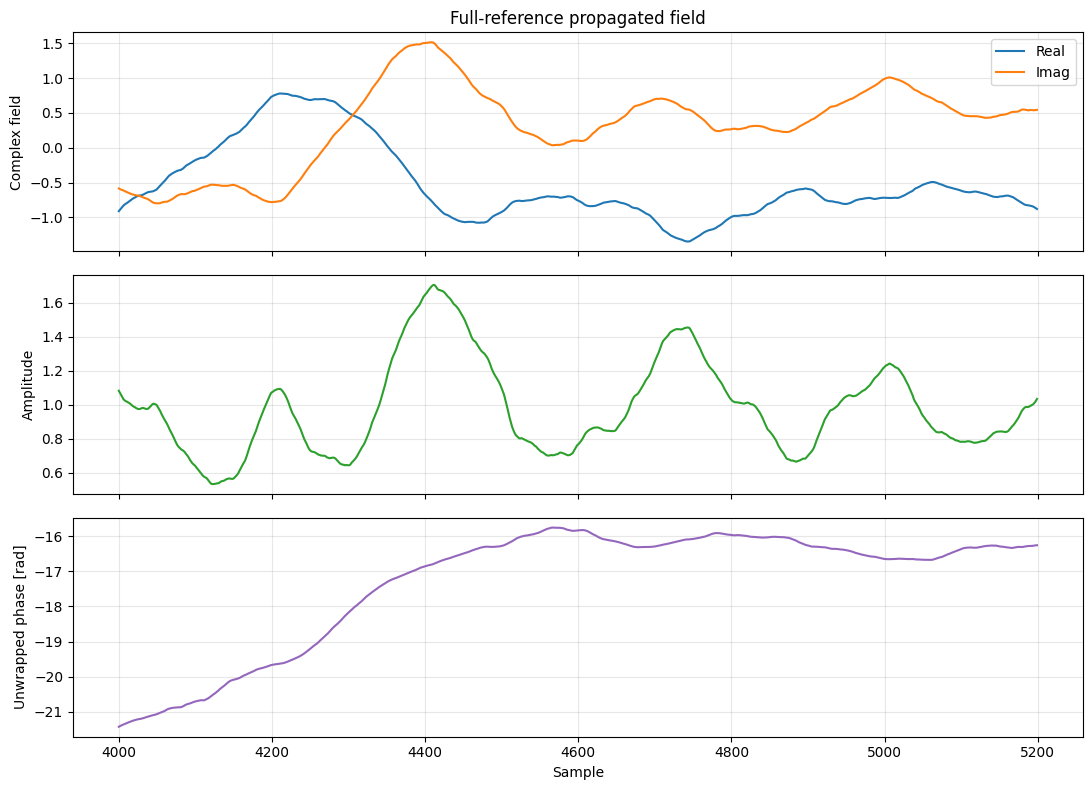

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
plot_start = config["plot_start"]
plot_stop = min(plot_start + config["n_plot"], N)
sl = slice(plot_start, plot_stop)
samples = np.arange(plot_start, plot_stop)

axes[0].plot(samples, np.real(psi_full[sl]), label="Real")
axes[0].plot(samples, np.imag(psi_full[sl]), label="Imag")
axes[0].set_ylabel("Complex field")
axes[0].set_title("Full-reference propagated field")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(samples, amp_full[sl], color="tab:green")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True, alpha=0.3)

axes[2].plot(samples, phase_full[sl], color="tab:purple")
axes[2].set_xlabel("Sample")
axes[2].set_ylabel("Unwrapped phase [rad]")
axes[2].grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(output_dir / "reference_field_overview.png", dpi=300)
plt.show()


## Centered Local FFT Sweep

The rectangular centered case tests only the corrected indexing/extraction. Smooth windows are included afterward to see whether leakage reduction improves phase behavior, with the caveat that windowing changes amplitude scaling.


In [5]:
centered_rows = []

for block_len in config["block_lengths"]:
    if block_len >= len(u):
        continue

    edge = config["edge_factor"] * block_len
    idx = make_valid_index(len(u), edge)

    for window in config["window_list"]:
        psi_center = centered_local_fft_propagation(
            u=u,
            rho_over_v=rho_over_v,
            dt=dt,
            block_len=block_len,
            window=window,
        )

        metrics = compute_field_metrics(psi_full, psi_center, idx)
        centered_rows.append(
            {
                "method": "centered_local_fft",
                "block_len": block_len,
                "window": "rectangular" if window is None else window,
                **metrics,
            }
        )

centered_df = pd.DataFrame(centered_rows)
centered_df.to_csv(output_dir / "centered_local_fft_sweep.csv", index=False)
centered_df


,method,block_len,window,num_valid_samples,field_rel_error,amp_rmse,phase_rmse_rad,real_rmse,imag_rmse,amp_corr
0,centered_local_fft,512,rectangular,14336,0.272294,0.187588,0.260313,0.186375,0.198447,0.850380
1,centered_local_fft,512,hann,14336,0.482477,0.362504,0.456017,0.330921,0.350983,0.603055
2,centered_local_fft,512,hamming,14336,0.454469,0.343894,0.418458,0.311831,0.330495,0.647532
3,centered_local_fft,512,tukey,14336,0.454923,0.327647,0.432149,0.312468,0.330518,0.576252
4,centered_local_fft,800,rectangular,13760,0.147826,0.101596,0.141591,0.104469,0.104990,0.959505
5,centered_local_fft,800,hann,13760,0.303973,0.229334,0.257448,0.213766,0.216932,0.835319
6,centered_local_fft,800,hamming,13760,0.281041,0.212217,0.240347,0.198278,0.199936,0.865038
7,centered_local_fft,800,tukey,13760,0.196535,0.135607,0.194632,0.144315,0.133969,0.921201
8,centered_local_fft,1024,rectangular,13312,0.099669,0.071529,0.096691,0.072000,0.068770,0.977848
9,centered_local_fft,1024,hann,13312,0.213853,0.158838,0.186617,0.152592,0.149513,0.924263


In [6]:
comparison_rows = []
causal_method_name = (
    "causal_nonnegative_lag_filter"
    if config["causal_include_zero_lag"]
    else "causal_positive_lag_filter"
)

for block_len in config["block_lengths"]:
    if block_len >= len(u):
        continue

    edge = config["edge_factor"] * block_len
    idx = make_valid_index(len(u), edge)

    psi_past = sliding_buffer_propagation(u, rho_over_v, dt, block_len)
    psi_causal = causal_filter_propagation(
        u, rho_over_v, dt, block_len, include_zero_lag=config["causal_include_zero_lag"]
    )
    psi_center = centered_local_fft_propagation(
        u=u,
        rho_over_v=rho_over_v,
        dt=dt,
        block_len=block_len,
        window=None,
    )

    for name, psi_hat in [
        ("past_only_last_sample_fft", psi_past),
        (causal_method_name, psi_causal),
        ("centered_center_sample_fft", psi_center),
    ]:
        metrics = compute_field_metrics(psi_full, psi_hat, idx)
        comparison_rows.append(
            {
                "method": name,
                "block_len": block_len,
                **metrics,
            }
        )

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(output_dir / "past_causal_vs_centered_local_fft.csv", index=False)
comparison_df


,method,block_len,num_valid_samples,field_rel_error,amp_rmse,phase_rmse_rad,real_rmse,imag_rmse,amp_corr
0,past_only_last_sample_fft,512,14336,0.860269,0.465901,1.248314,0.586183,0.629427,0.304045
1,centered_center_sample_fft,512,14336,0.272294,0.187588,0.260313,0.186375,0.198447,0.850380
2,past_only_last_sample_fft,800,13760,0.825640,0.486144,1.067902,0.559886,0.608962,0.231443
3,centered_center_sample_fft,800,13760,0.147826,0.101596,0.141591,0.104469,0.104990,0.959505
4,past_only_last_sample_fft,1024,13312,0.832482,0.509285,1.107045,0.596463,0.579505,0.176494
5,centered_center_sample_fft,1024,13312,0.099669,0.071529,0.096691,0.072000,0.068770,0.977848
6,past_only_last_sample_fft,1500,12360,0.797323,0.463695,1.086088,0.529715,0.602197,0.300145
7,centered_center_sample_fft,1500,12360,0.054369,0.039187,0.050376,0.039049,0.038289,0.993670
8,past_only_last_sample_fft,2000,11360,0.816777,0.491215,1.030704,0.513069,0.633015,0.166347
9,centered_center_sample_fft,2000,11360,0.044687,0.032318,0.044844,0.031529,0.031516,0.995727


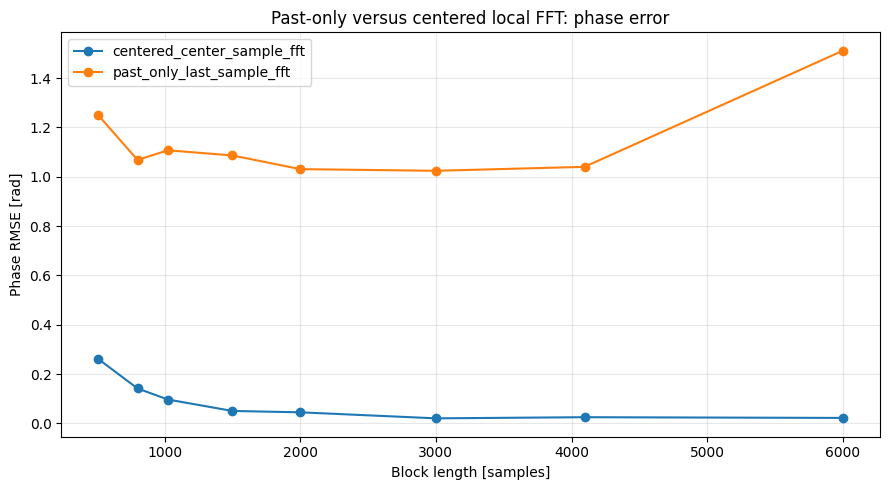

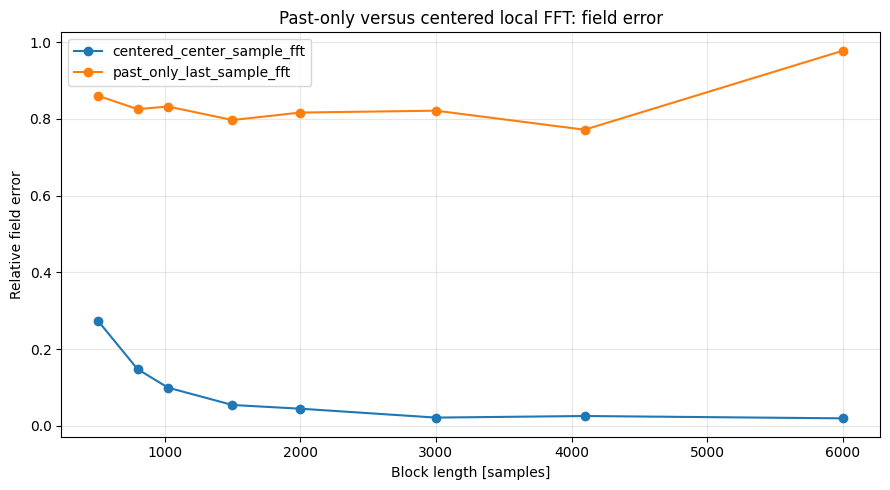

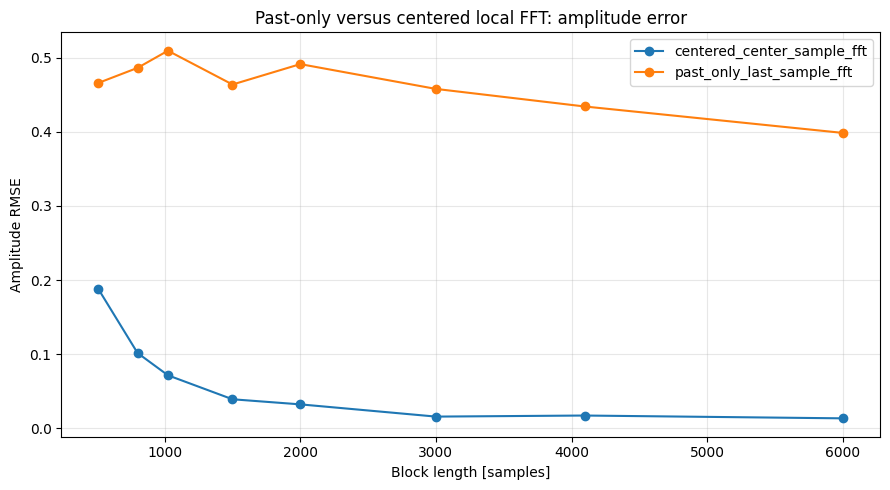

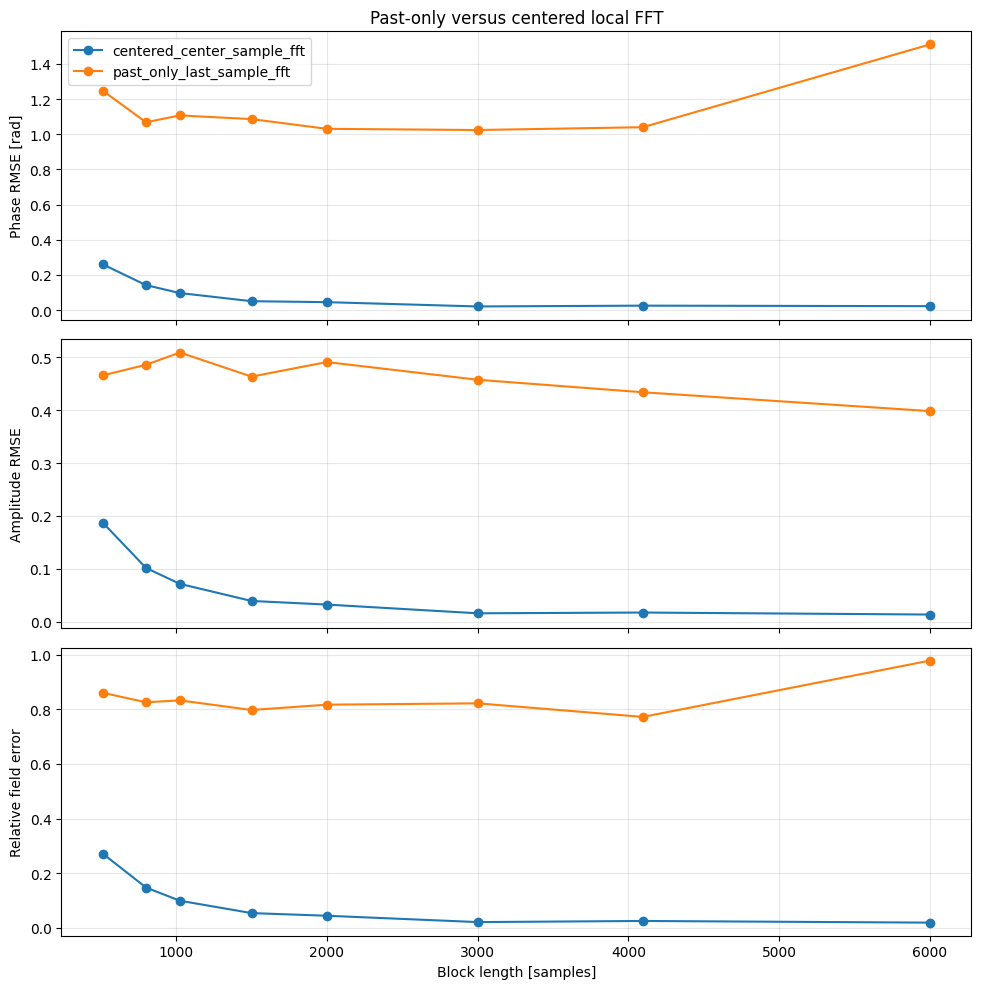

In [7]:
valid_comparison_df = comparison_df.dropna(subset=["field_rel_error", "phase_rmse_rad", "amp_rmse"])

for metric, ylabel, title, filename in [
    ("phase_rmse_rad", "Phase RMSE [rad]", "Past-only, causal, and centered local FFT: phase error", "past_causal_vs_centered_phase_error.png"),
    ("field_rel_error", "Relative field error", "Past-only, causal, and centered local FFT: field error", "past_causal_vs_centered_field_error.png"),
    ("amp_rmse", "Amplitude RMSE", "Past-only, causal, and centered local FFT: amplitude error", "past_causal_vs_centered_amplitude_error.png"),
]:
    fig, ax = plt.subplots(figsize=(9, 5))
    for method, group in valid_comparison_df.groupby("method"):
        group = group.sort_values("block_len")
        ax.plot(group["block_len"], group[metric], marker="o", label=method)
    ax.set_xlabel("Block length [samples]")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(output_dir / filename, dpi=300)
    plt.show()

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
for ax, metric, ylabel in [
    (axes[0], "phase_rmse_rad", "Phase RMSE [rad]"),
    (axes[1], "amp_rmse", "Amplitude RMSE"),
    (axes[2], "field_rel_error", "Relative field error"),
]:
    for method, group in valid_comparison_df.groupby("method"):
        group = group.sort_values("block_len")
        ax.plot(group["block_len"], group[metric], marker="o", label=method)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
axes[0].set_title("Past-only, causal, and centered local FFT")
axes[-1].set_xlabel("Block length [samples]")
axes[0].legend()
fig.tight_layout()
fig.savefig(output_dir / "past_causal_vs_centered_error_summary.png", dpi=300)
plt.show()


In [8]:
valid_centered_df = centered_df.dropna(subset=["field_rel_error", "phase_rmse_rad", "amp_rmse"])
best_phase_df = valid_centered_df.sort_values("phase_rmse_rad").head(10)
best_field_df = valid_centered_df.sort_values("field_rel_error").head(10)
best_causal_df = (
    valid_comparison_df[valid_comparison_df["method"].str.startswith("causal_")]
    .sort_values("phase_rmse_rad")
    .head(10)
)

best_phase_df.to_csv(output_dir / "best_centered_phase_configurations.csv", index=False)
best_field_df.to_csv(output_dir / "best_centered_field_configurations.csv", index=False)
best_causal_df.to_csv(output_dir / "best_causal_phase_configurations.csv", index=False)

best_phase_df


,method,block_len,window,num_valid_samples,field_rel_error,amp_rmse,phase_rmse_rad,real_rmse,imag_rmse,amp_corr
31,centered_local_fft,6000,tukey,3360,0.006414,0.004657,0.006625,0.004432,0.004635,0.999924
27,centered_local_fft,4096,tukey,7168,0.010880,0.007800,0.009782,0.007689,0.007717,0.999736
30,centered_local_fft,6000,hamming,3360,0.012624,0.009566,0.011343,0.009223,0.008619,0.999732
29,centered_local_fft,6000,hann,3360,0.013430,0.010168,0.011828,0.009750,0.009234,0.999696
23,centered_local_fft,3000,tukey,9360,0.017040,0.012560,0.015830,0.012320,0.011765,0.999358
26,centered_local_fft,4096,hamming,7168,0.021948,0.016134,0.018024,0.015506,0.015570,0.999112
25,centered_local_fft,4096,hann,7168,0.023433,0.017397,0.019124,0.016565,0.016614,0.998975
20,centered_local_fft,3000,rectangular,9360,0.021501,0.015818,0.020437,0.015194,0.015204,0.998990
28,centered_local_fft,6000,rectangular,3360,0.019551,0.013472,0.022145,0.012261,0.015226,0.999381
24,centered_local_fft,4096,rectangular,7168,0.025604,0.017263,0.025045,0.017160,0.019045,0.998746


## Best Causal Method Behavior

The best causal configuration is selected by phase RMSE from the one-sided support sweep. These plots show the propagated field, amplitude, phase, and errors for the selected causal block length.


In [ ]:
best_causal = best_causal_df.iloc[0]
best_causal_block_len = int(best_causal["block_len"])
psi_best_causal = causal_filter_propagation(
    u=u,
    rho_over_v=rho_over_v,
    dt=dt,
    block_len=best_causal_block_len,
    include_zero_lag=config["causal_include_zero_lag"],
)

plot_start = config["plot_start"]
plot_stop = min(plot_start + config["n_plot"], N)
sl = slice(plot_start, plot_stop)
samples = np.arange(plot_start, plot_stop)

phase_best_causal = np.unwrap(np.angle(psi_best_causal))
causal_phase_error = np.angle(psi_best_causal * np.conj(psi_full))
causal_amp_error = np.abs(psi_best_causal) - np.abs(psi_full)

causal_method_summary = {
    "selected_by": "phase_rmse_rad",
    "method": best_causal["method"],
    "block_len": best_causal_block_len,
    "causal_include_zero_lag": bool(config["causal_include_zero_lag"]),
    "latency_samples": 0,
    "latency_s": 0.0,
    "warmup_samples": int((best_causal_block_len + 1) // 2 - 1),
    "field_rel_error": float(best_causal["field_rel_error"]),
    "amp_rmse": float(best_causal["amp_rmse"]),
    "phase_rmse_rad": float(best_causal["phase_rmse_rad"]),
    "amp_corr": float(best_causal["amp_corr"]),
}
pd.DataFrame([causal_method_summary]).to_csv(output_dir / "best_causal_method_summary.csv", index=False)
causal_method_summary


In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(11, 12), sharex=True)
fig.suptitle(
    f"Best causal one-sided filter: M={best_causal_block_len}, method={best_causal['method']}",
    y=0.995,
)

axes[0].plot(samples, np.real(psi_full[sl]), "k", linewidth=2, label="Full reference")
axes[0].plot(samples, np.real(psi_best_causal[sl]), "--", label="Causal one-sided filter")
axes[0].set_ylabel("Real part")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(samples, np.imag(psi_full[sl]), "k", linewidth=2, label="Full reference")
axes[1].plot(samples, np.imag(psi_best_causal[sl]), "--", label="Causal one-sided filter")
axes[1].set_ylabel("Imaginary part")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

axes[2].plot(samples, np.abs(psi_full[sl]), "k", linewidth=2, label="Full reference")
axes[2].plot(samples, np.abs(psi_best_causal[sl]), "--", label="Causal one-sided filter")
axes[2].set_ylabel("Amplitude")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

axes[3].plot(samples, phase_full[sl], "k", linewidth=2, label="Full reference")
axes[3].plot(samples, phase_best_causal[sl], "--", label="Causal one-sided filter")
axes[3].set_xlabel("Sample")
axes[3].set_ylabel("Unwrapped phase [rad]")
axes[3].grid(True, alpha=0.3)
axes[3].legend()

fig.tight_layout()
fig.savefig(output_dir / "best_causal_method_timeseries.png", dpi=300)
plt.show()


In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(samples, causal_phase_error[sl])
axes[0].set_ylabel("Wrapped phase error [rad]")
axes[0].set_title("Best causal one-sided filter errors")
axes[0].grid(True, alpha=0.3)

axes[1].plot(samples, causal_amp_error[sl])
axes[1].set_xlabel("Sample")
axes[1].set_ylabel("Amplitude error")
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(output_dir / "best_causal_method_error_timeseries.png", dpi=300)
plt.show()


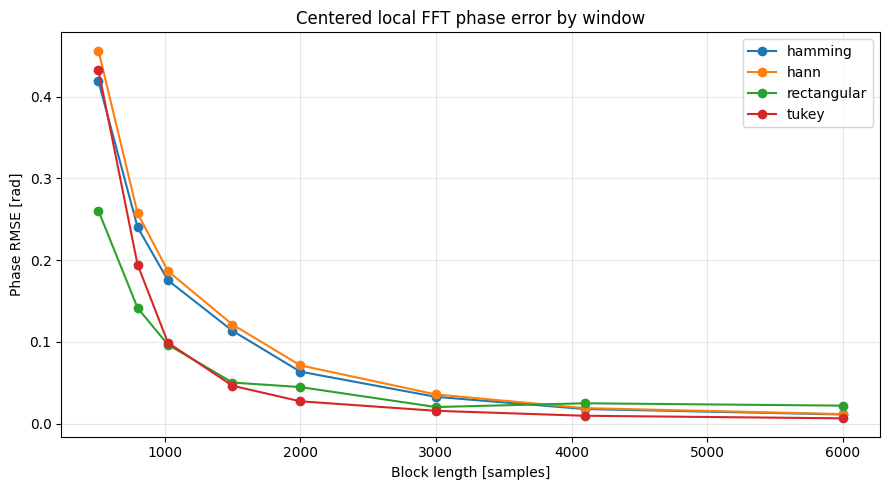

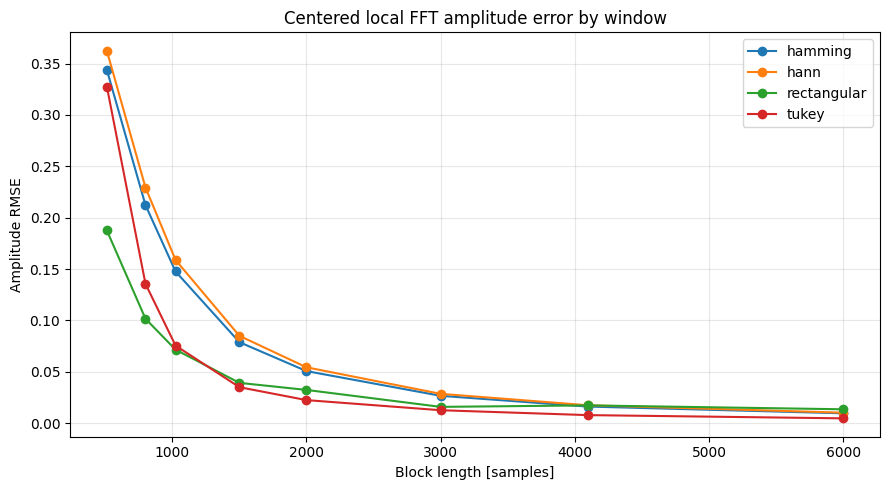

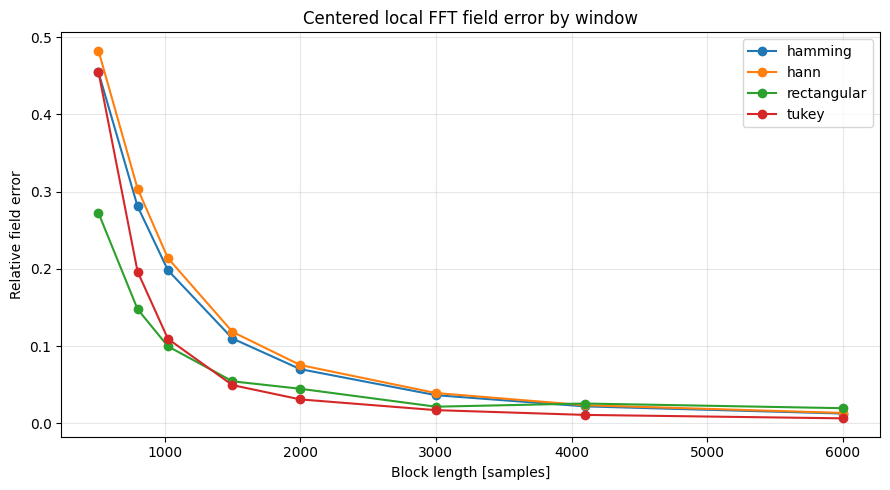

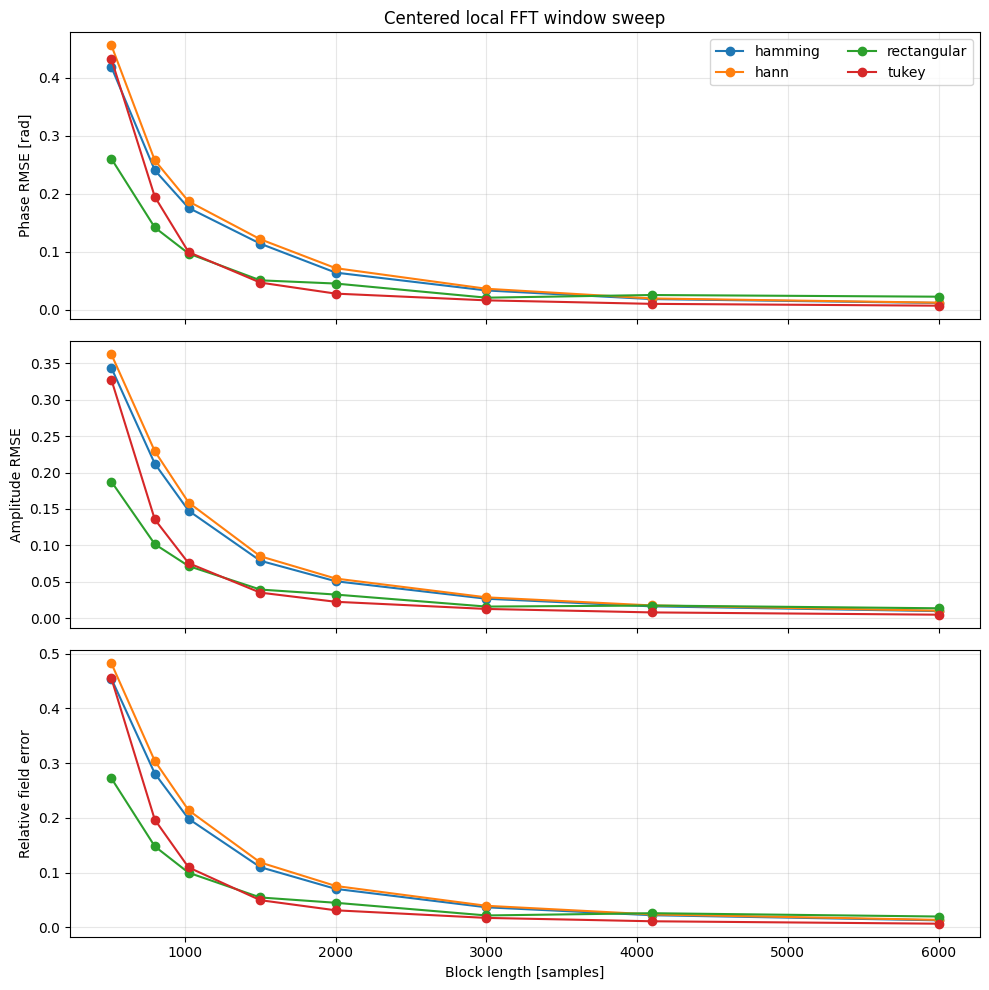

In [9]:
for metric, ylabel, title, filename in [
    ("phase_rmse_rad", "Phase RMSE [rad]", "Centered local FFT phase error by window", "centered_window_phase_error.png"),
    ("amp_rmse", "Amplitude RMSE", "Centered local FFT amplitude error by window", "centered_window_amplitude_error.png"),
    ("field_rel_error", "Relative field error", "Centered local FFT field error by window", "centered_window_field_error.png"),
]:
    fig, ax = plt.subplots(figsize=(9, 5))
    for window, group in valid_centered_df.groupby("window"):
        group = group.sort_values("block_len")
        ax.plot(group["block_len"], group[metric], marker="o", label=window)
    ax.set_xlabel("Block length [samples]")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(output_dir / filename, dpi=300)
    plt.show()

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
for ax, metric, ylabel in [
    (axes[0], "phase_rmse_rad", "Phase RMSE [rad]"),
    (axes[1], "amp_rmse", "Amplitude RMSE"),
    (axes[2], "field_rel_error", "Relative field error"),
]:
    for window, group in valid_centered_df.groupby("window"):
        group = group.sort_values("block_len")
        ax.plot(group["block_len"], group[metric], marker="o", label=window)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
axes[0].set_title("Centered local FFT window sweep")
axes[-1].set_xlabel("Block length [samples]")
axes[0].legend(ncol=2)
fig.tight_layout()
fig.savefig(output_dir / "centered_window_error_summary.png", dpi=300)
plt.show()


## Best Centered Method Behavior

The best centered configuration is selected by phase RMSE. This is the most relevant single diagnostic for carrier tracking, but the amplitude behavior is plotted alongside it because prompt amplitude is also part of the tracking observable.


In [10]:
best = best_phase_df.iloc[0]
best_window = None if best["window"] == "rectangular" else best["window"]
psi_best_center = centered_local_fft_propagation(
    u=u,
    rho_over_v=rho_over_v,
    dt=dt,
    block_len=int(best["block_len"]),
    window=best_window,
)

plot_start = config["plot_start"]
plot_stop = min(plot_start + config["n_plot"], N)
sl = slice(plot_start, plot_stop)
samples = np.arange(plot_start, plot_stop)

phase_best_center = np.unwrap(np.angle(psi_best_center))
phase_error = np.angle(psi_best_center * np.conj(psi_full))
amp_error = np.abs(psi_best_center) - np.abs(psi_full)

method_summary = {
    "selected_by": "phase_rmse_rad",
    "method": "centered_local_fft",
    "block_len": int(best["block_len"]),
    "window": best["window"],
    "latency_samples": int(best["block_len"] // 2),
    "latency_s": float((best["block_len"] // 2) * dt),
    "field_rel_error": float(best["field_rel_error"]),
    "amp_rmse": float(best["amp_rmse"]),
    "phase_rmse_rad": float(best["phase_rmse_rad"]),
    "amp_corr": float(best["amp_corr"]),
}
pd.DataFrame([method_summary]).to_csv(output_dir / "best_centered_method_summary.csv", index=False)
method_summary


{'selected_by': 'phase_rmse_rad',
 'method': 'centered_local_fft',
 'block_len': 6000,
 'window': 'tukey',
 'latency_samples': 3000,
 'latency_s': 60.0,
 'field_rel_error': 0.0064137235795190236,
 'amp_rmse': 0.004657177911421618,
 'phase_rmse_rad': 0.00662452515253849,
 'amp_corr': 0.999923518537839}

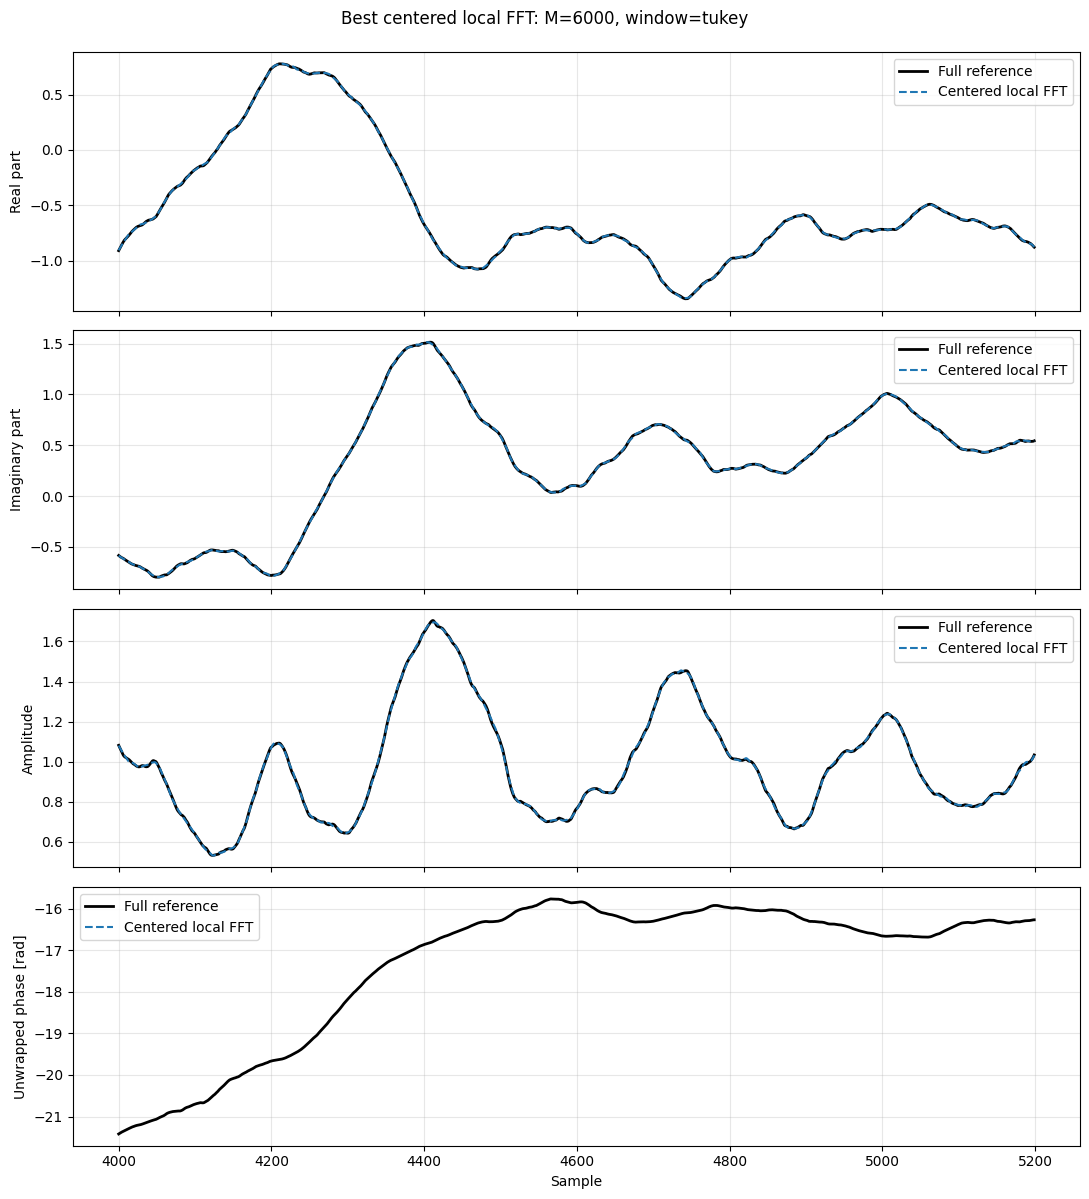

In [11]:
fig, axes = plt.subplots(4, 1, figsize=(11, 12), sharex=True)
fig.suptitle(
    f"Best centered local FFT: M={int(best['block_len'])}, window={best['window']}",
    y=0.995,
)

axes[0].plot(samples, np.real(psi_full[sl]), "k", linewidth=2, label="Full reference")
axes[0].plot(samples, np.real(psi_best_center[sl]), "--", label="Centered local FFT")
axes[0].set_ylabel("Real part")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(samples, np.imag(psi_full[sl]), "k", linewidth=2, label="Full reference")
axes[1].plot(samples, np.imag(psi_best_center[sl]), "--", label="Centered local FFT")
axes[1].set_ylabel("Imaginary part")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

axes[2].plot(samples, np.abs(psi_full[sl]), "k", linewidth=2, label="Full reference")
axes[2].plot(samples, np.abs(psi_best_center[sl]), "--", label="Centered local FFT")
axes[2].set_ylabel("Amplitude")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

axes[3].plot(samples, phase_full[sl], "k", linewidth=2, label="Full reference")
axes[3].plot(samples, phase_best_center[sl], "--", label="Centered local FFT")
axes[3].set_xlabel("Sample")
axes[3].set_ylabel("Unwrapped phase [rad]")
axes[3].grid(True, alpha=0.3)
axes[3].legend()

fig.tight_layout()
fig.savefig(output_dir / "best_centered_method_timeseries.png", dpi=300)
plt.show()


## All Causal Block-Length Time Series

These figures overlay every tested causal one-sided filter block length, so the causal block-size dependence is visible directly in the propagated field, amplitude, and phase traces.


In [ ]:
psi_causal_by_block_len = {
    block_len: causal_filter_propagation(
        u=u,
        rho_over_v=rho_over_v,
        dt=dt,
        block_len=block_len,
        include_zero_lag=config["causal_include_zero_lag"],
    )
    for block_len in config["block_lengths"]
    if block_len < len(u)
}

fig, axes = plt.subplots(4, 1, figsize=(12, 13), sharex=True)
fig.suptitle(f"Causal one-sided propagated fields, method={causal_method_name}", y=0.995)

axes[0].plot(samples, np.real(psi_full[sl]), "k", linewidth=2.2, label="Full reference")
axes[1].plot(samples, np.imag(psi_full[sl]), "k", linewidth=2.2, label="Full reference")
axes[2].plot(samples, np.abs(psi_full[sl]), "k", linewidth=2.2, label="Full reference")
axes[3].plot(samples, phase_full[sl], "k", linewidth=2.2, label="Full reference")

colors = plt.cm.plasma(np.linspace(0.05, 0.95, len(psi_causal_by_block_len)))
for color, (block_len, psi_hat) in zip(colors, psi_causal_by_block_len.items()):
    phase_hat_slice = np.unwrap(np.angle(psi_hat[sl]))
    label = f"M={block_len}"
    axes[0].plot(samples, np.real(psi_hat[sl]), "--", color=color, linewidth=1.1, label=label)
    axes[1].plot(samples, np.imag(psi_hat[sl]), "--", color=color, linewidth=1.1, label=label)
    axes[2].plot(samples, np.abs(psi_hat[sl]), "--", color=color, linewidth=1.1, label=label)
    axes[3].plot(samples, phase_hat_slice, "--", color=color, linewidth=1.1, label=label)

axes[0].set_ylabel("Real part")
axes[1].set_ylabel("Imaginary part")
axes[2].set_ylabel("Amplitude")
axes[3].set_ylabel("Unwrapped phase [rad]")
axes[3].set_xlabel("Sample")

for ax in axes:
    ax.grid(True, alpha=0.3)

axes[0].legend(ncol=5, fontsize=8)
fig.tight_layout()
fig.savefig(output_dir / f"all_causal_block_lengths_{causal_method_name}.png", dpi=300)
plt.show()


## All Centered Block-Length Time Series

The best-method plot above shows one selected configuration. The figures below overlay every tested centered local FFT block length for each window type, so the block-size dependence is visible directly in the propagated field, amplitude, and phase traces.


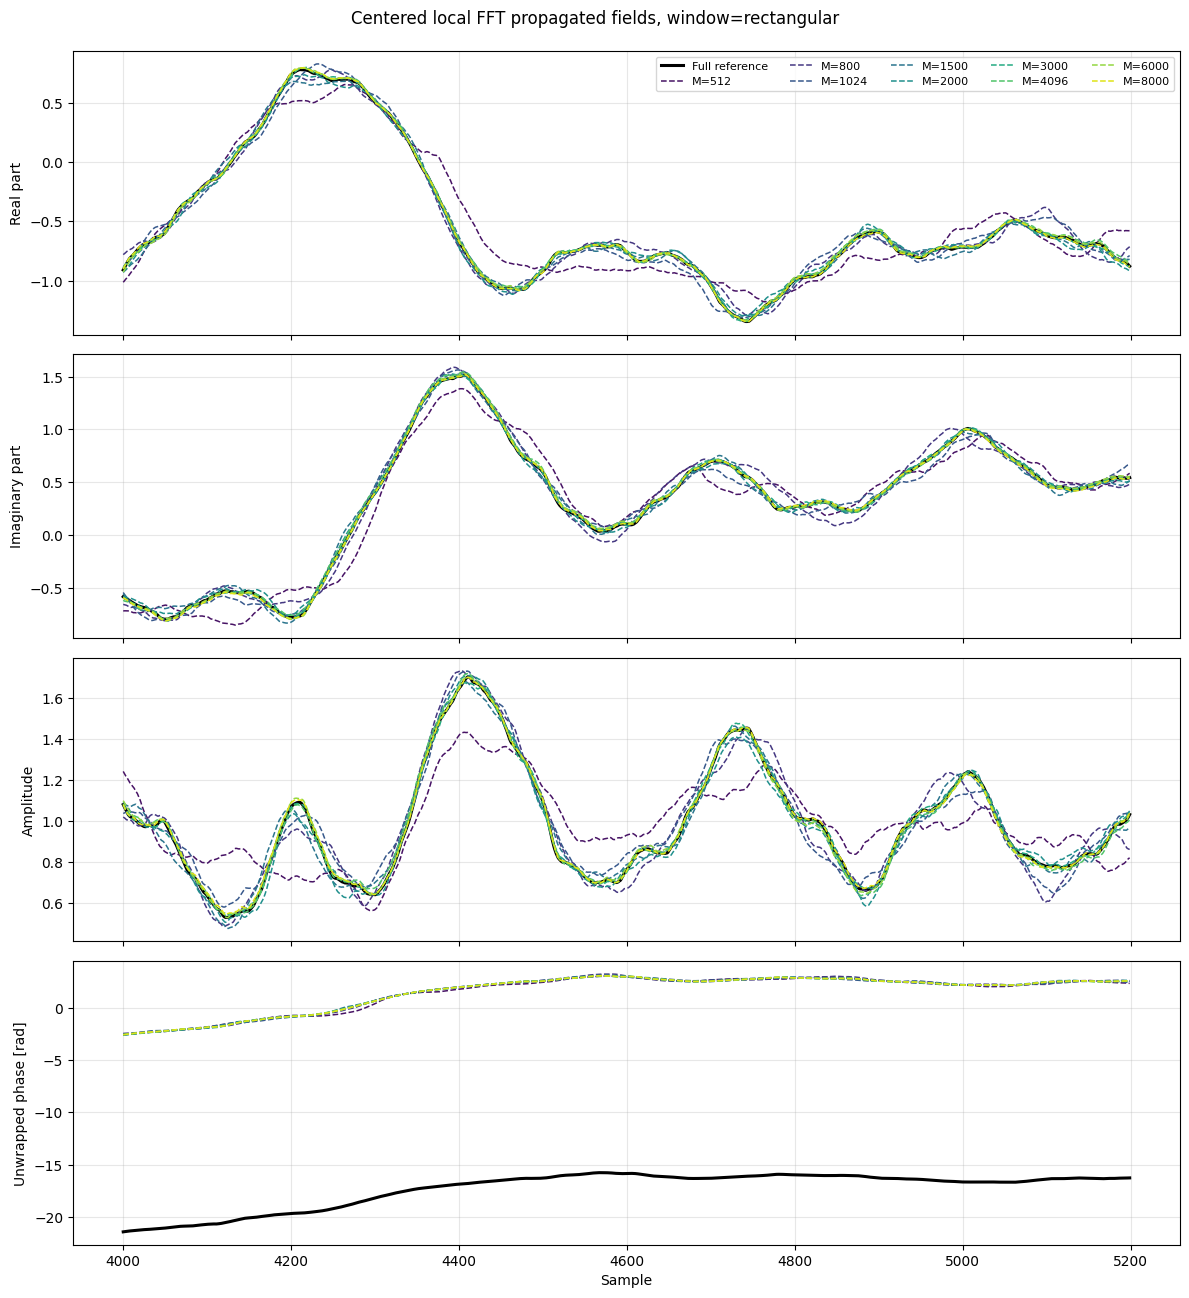

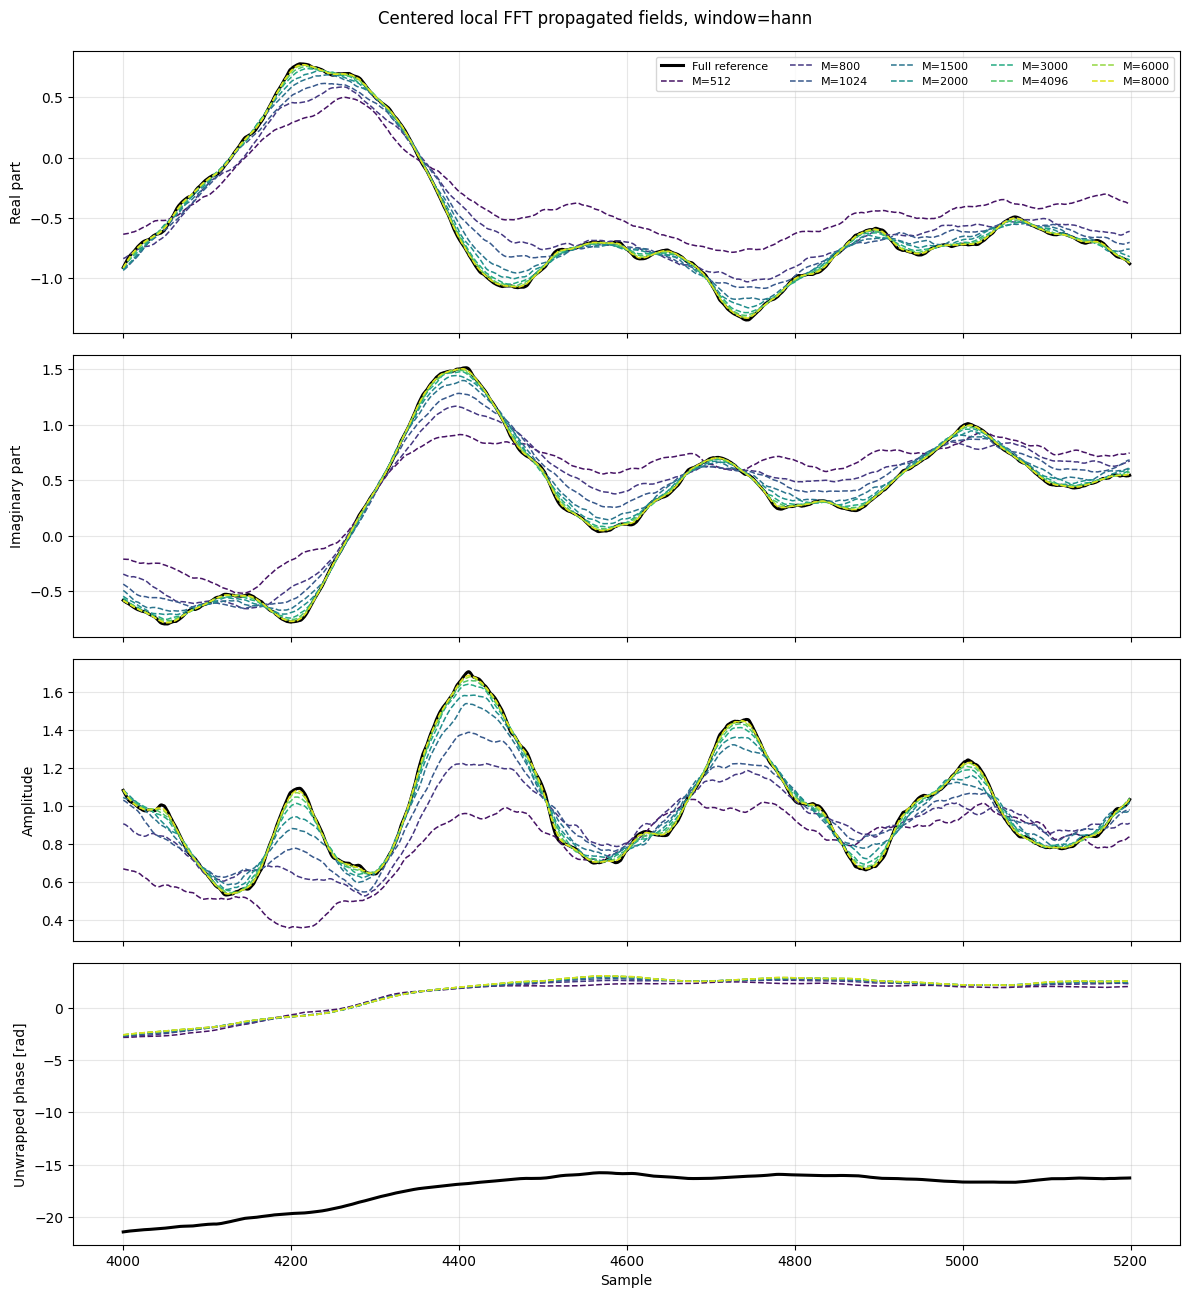

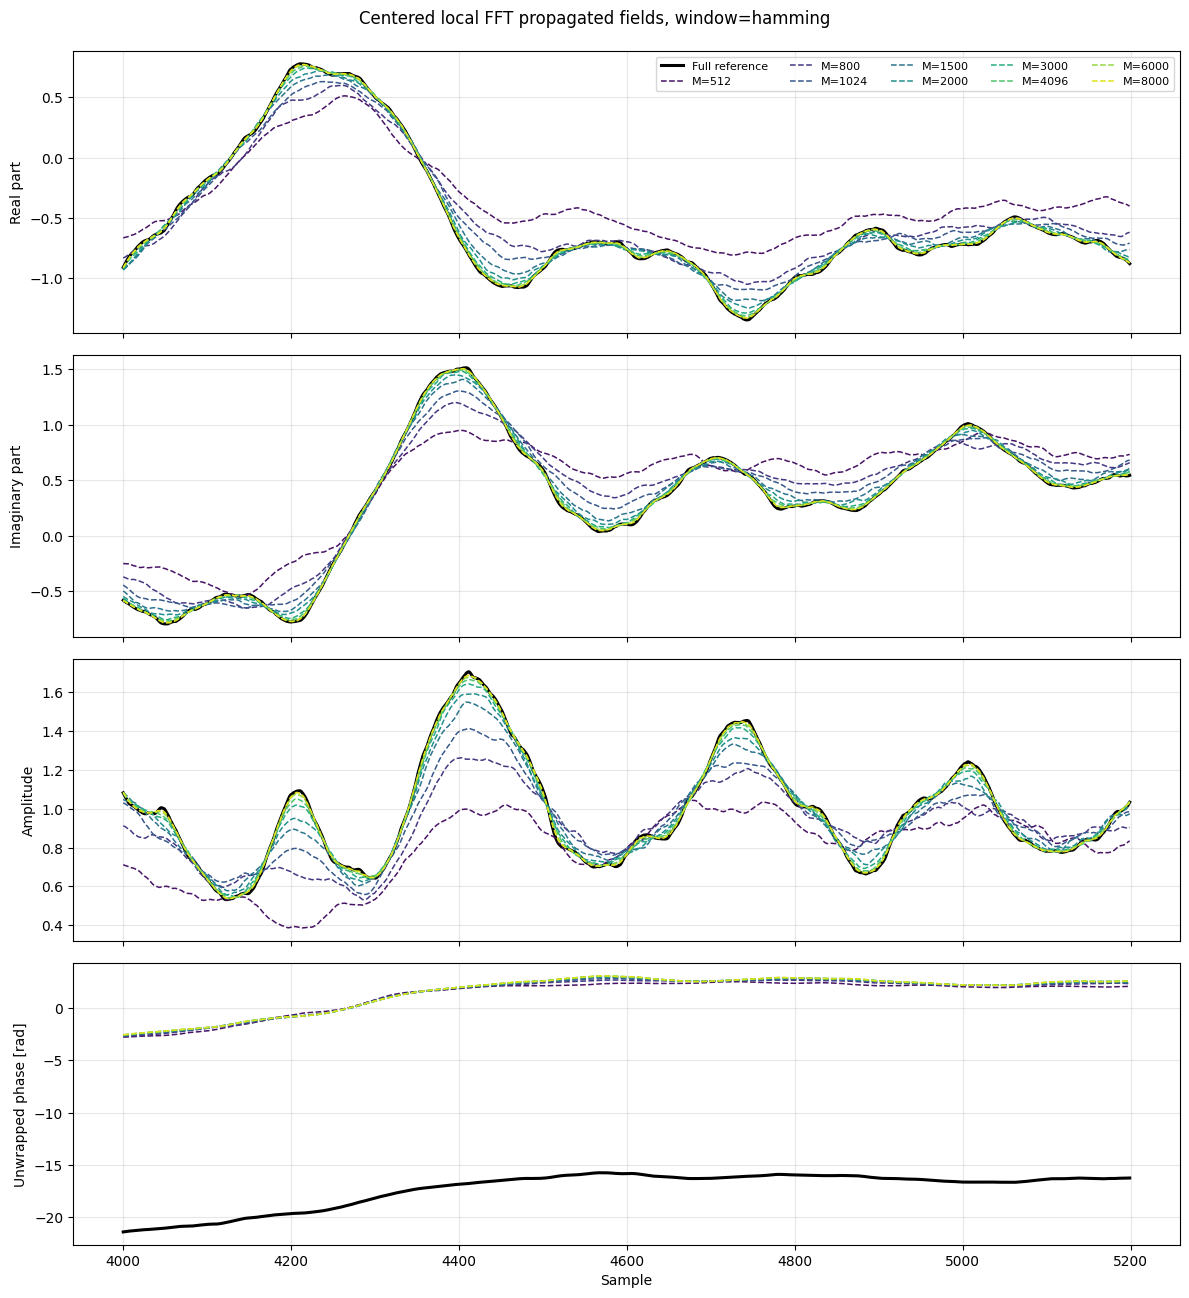

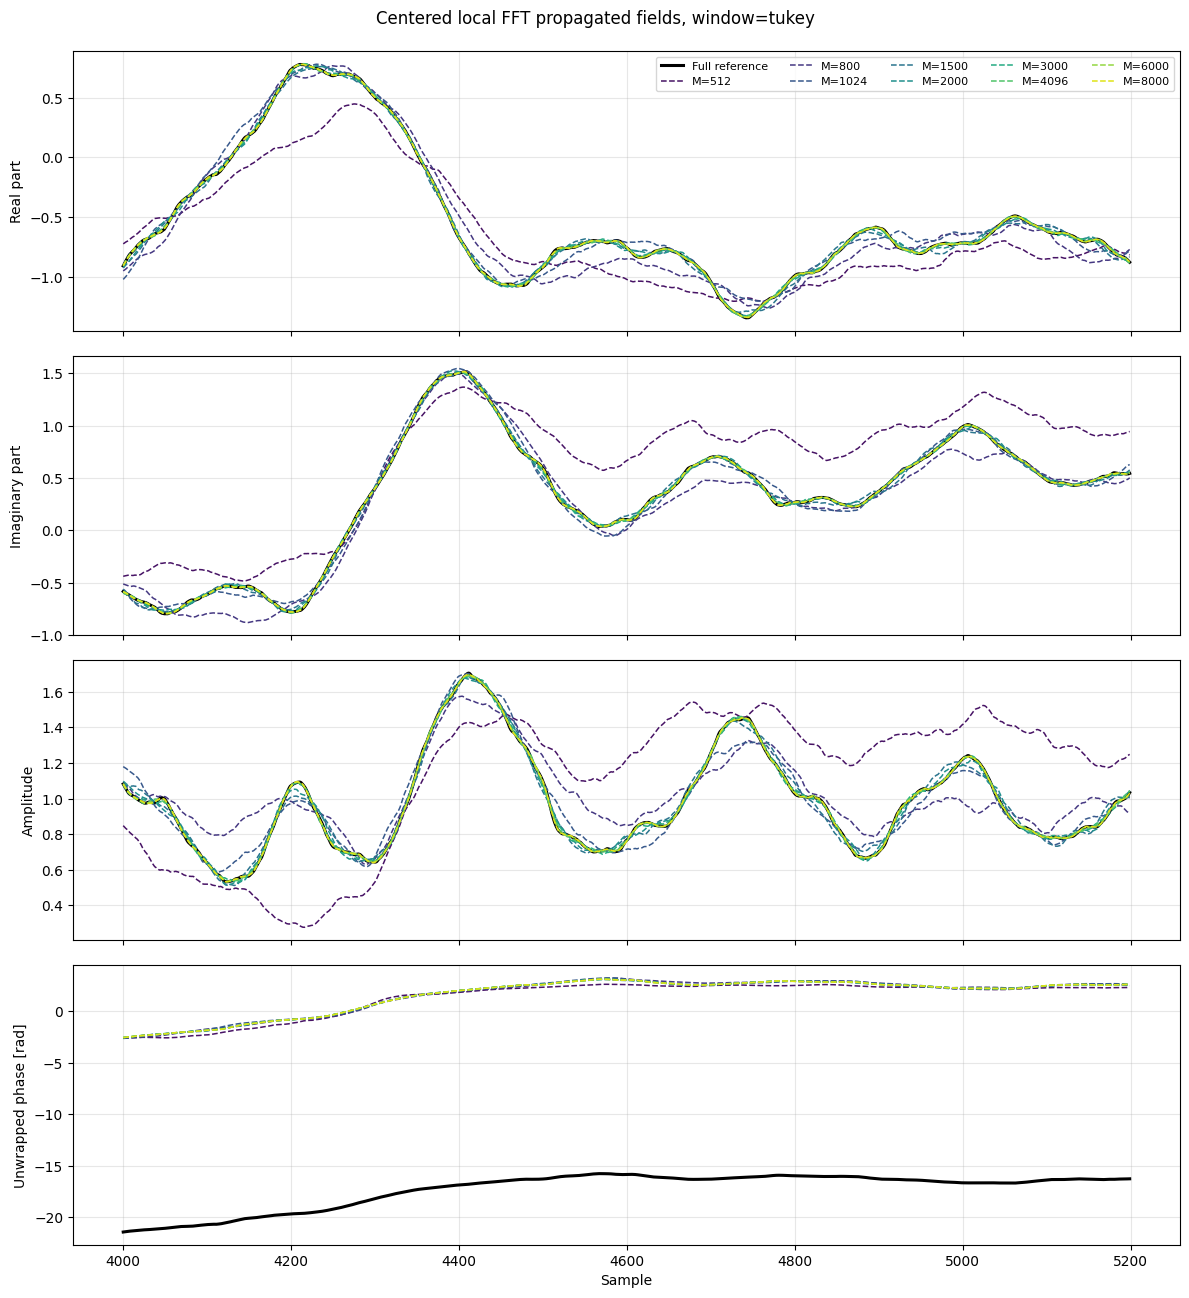

In [12]:
for window in config["window_list"]:
    window_label = "rectangular" if window is None else window
    psi_by_block_len = {
        block_len: centered_local_fft_propagation(
            u=u,
            rho_over_v=rho_over_v,
            dt=dt,
            block_len=block_len,
            window=window,
        )
        for block_len in config["block_lengths"]
        if block_len < len(u)
    }

    fig, axes = plt.subplots(4, 1, figsize=(12, 13), sharex=True)
    fig.suptitle(f"Centered local FFT propagated fields, window={window_label}", y=0.995)

    axes[0].plot(samples, np.real(psi_full[sl]), "k", linewidth=2.2, label="Full reference")
    axes[1].plot(samples, np.imag(psi_full[sl]), "k", linewidth=2.2, label="Full reference")
    axes[2].plot(samples, np.abs(psi_full[sl]), "k", linewidth=2.2, label="Full reference")
    axes[3].plot(samples, phase_full[sl], "k", linewidth=2.2, label="Full reference")

    colors = plt.cm.viridis(np.linspace(0.05, 0.95, len(psi_by_block_len)))
    for color, (block_len, psi_hat) in zip(colors, psi_by_block_len.items()):
        phase_hat_slice = np.unwrap(np.angle(psi_hat[sl]))
        label = f"M={block_len}"
        axes[0].plot(samples, np.real(psi_hat[sl]), "--", color=color, linewidth=1.1, label=label)
        axes[1].plot(samples, np.imag(psi_hat[sl]), "--", color=color, linewidth=1.1, label=label)
        axes[2].plot(samples, np.abs(psi_hat[sl]), "--", color=color, linewidth=1.1, label=label)
        axes[3].plot(samples, phase_hat_slice, "--", color=color, linewidth=1.1, label=label)

    axes[0].set_ylabel("Real part")
    axes[1].set_ylabel("Imaginary part")
    axes[2].set_ylabel("Amplitude")
    axes[3].set_ylabel("Unwrapped phase [rad]")
    axes[3].set_xlabel("Sample")

    for ax in axes:
        ax.grid(True, alpha=0.3)

    axes[0].legend(ncol=5, fontsize=8)
    fig.tight_layout()
    fig.savefig(output_dir / f"all_centered_block_lengths_window_{window_label}.png", dpi=300)
    plt.show()


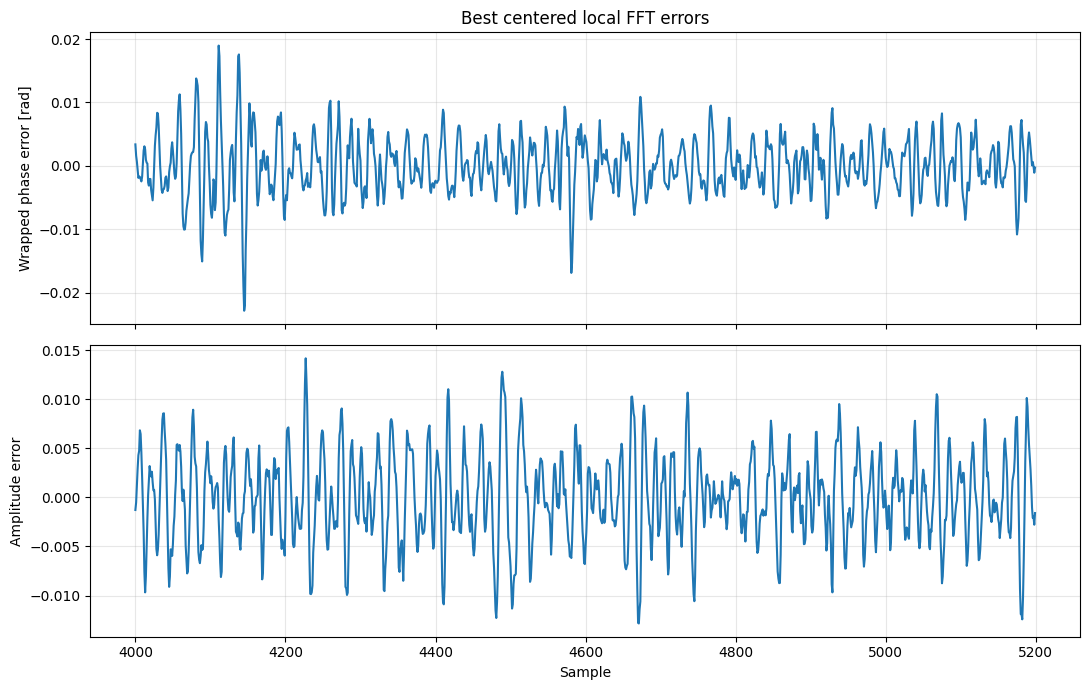

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(samples, phase_error[sl])
axes[0].set_ylabel("Wrapped phase error [rad]")
axes[0].set_title("Best centered local FFT errors")
axes[0].grid(True, alpha=0.3)

axes[1].plot(samples, amp_error[sl])
axes[1].set_xlabel("Sample")
axes[1].set_ylabel("Amplitude error")
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(output_dir / "best_centered_method_error_timeseries.png", dpi=300)
plt.show()


## Interpretation

If the causal one-sided filter is much better than the past-only FFT baseline, then the previous failure was partly caused by keeping wrapped negative-lag support in a filter that was being used causally.

If the centered local FFT is much better than both causal methods, then the propagation operator is materially noncausal over the tested band and a sample-by-sample zero-latency CKF update is not a good match for this operator.

If the causal filter is acceptable at moderate block length, then the CKF can use it directly with no future samples. If only the centered local FFT works, then the CKF can use a delayed measurement update with latency approximately

\[
\mathrm{latency} \approx \frac{M}{2}T_s.
\]

This is more appropriate than a zero-latency sample-by-sample CKF only if the phase and amplitude errors are acceptable at a tolerable latency.
